# 조건별 평가와 오류 분류

**이 노트북에서 할 일**

1. 개발 분할 15문항의 세 지표를 난이도와 질문 갈래로 나눠 평균합니다.
2. 값이 낮은 질문에 검색 단계 이름을 붙이고 이름별로 몇 개인지 셉니다.
3. Ch 10 08절 기록 여섯 줄을 나누기 방식과 겹침으로 나눠 같은 지표를 냅니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 열일곱 번입니다.
색인 한 벌에 한 번, 질문 검색에 열다섯 번, 묶은 함수 확인에 한 번입니다.

04절보다 한 번 많습니다. 마지막 절에서 함수 하나를 확인하며 질문 하나를 다시 검색하기 때문입니다.
답을 쓰는 모델은 이 절에서 부르지 않습니다.

보낼 조각 수는 색인이 59190개 어림이고 질문은 한 번에 스무 개 안팎입니다.
예상 비용은 열일곱 번을 합쳐 0.01달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)의 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

**데이터** — 읽는 파일은 네 갈래이고 모두 실습 묶음에 들어 있습니다.

- 말뭉치 `labs/data/rag-corpus/pdf/`의 디지털 PDF 18건과 `labs/data/rag-corpus/manifest.json`
- 평가셋 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`
- Ch 9 06절 기록 `labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl`
- Ch 10 08절 기록 `labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl`

이 절은 파일을 쓰지 않습니다. 02~04절과 같은 기준선을 같은 코드로 다시 만듭니다.

**강의와 실습 범위** — 강의 시간에는 2·6~10절을 설명합니다.
나눠 볼 조건 칸, 질문마다 세 지표 담기, 묶어서 평균 내기, 오류 이름 붙이기입니다.
3절 지표 함수와 4절 색인 만들기는 02~04절과 같은 코드라 실행만 하고 넘어갑니다.
11~13절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 고정한 패키지는 다섯 개입니다.

- 쪽 읽기: pypdf 6.1.1
- 색인과 임베딩: langchain-core 1.6.2 · langchain-openai 1.6.0
- 코사인 유사도 계산: numpy 2.5.3
- 키 읽기: python-dotenv 1.2.3

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch11-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

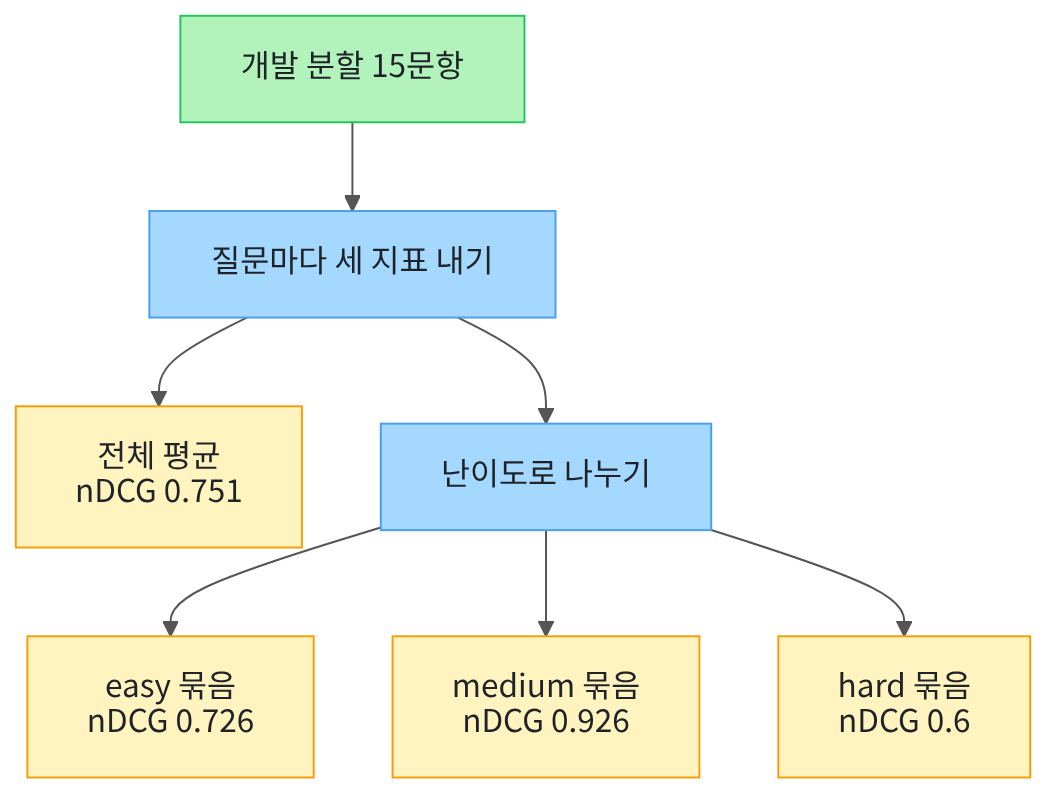

맨 위 초록 상자가 이 절의 입력입니다. 04절까지 쓴 개발 분할 15문항 그대로입니다.
그 아래 파란 상자에서 질문마다 세 지표를 냅니다.
왼쪽 노란 상자가 04절에서 낸 전체 평균이고, 오른쪽 파란 상자가 이 절이 더하는 일입니다.
맨 아래 노란 상자 세 개가 난이도로 나눈 뒤의 값입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
02~04절에서 쓴 다섯 개와 같습니다. 이 절도 같은 색인을 다시 만들기 때문입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.1.1" "langchain-core==1.6.2" "langchain-openai==1.6.0" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.1.1
langchain-core: 1.6.2
langchain-openai: 1.6.0
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 다섯 줄 가운데 첫 줄은 `pypdf: 6.1.1`입니다.
둘째 줄 `langchain-core: 1.6.2`와 셋째 줄 `langchain-openai: 1.6.0`도 보세요.
넷째 줄 `numpy: 2.5.3`은 색인이 코사인 유사도를 계산할 때 쓰는 패키지입니다.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다. 04절과 같은 목록입니다.

In [2]:
# 평가셋 읽기·로그 계산·PDF 읽기·문서 객체·임베딩·색인에 쓸 이름을 불러옵니다
import json
import math

from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from pypdf import PdfReader

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.
모듈 `math`는 04절에서 자리 무게를 만들 때 쓴 그 모듈입니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.
이 셀은 모듈 `os`도 함께 불러옵니다. 다음 셀에서 파일이 있는지 확인할 때 씁니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~04절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 고른 경로에 파일 이름을 이어 붙여 네 갈래 경로를 만듭니다.

In [5]:
# 이 절에서 읽을 파일 네 갈래의 경로를 만듭니다
corpus_path = root_path + "/labs/data/rag-corpus"
manifest_path = corpus_path + "/manifest.json"
dataset_path = root_path + "/labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
ch09_log_path = root_path + "/labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl"
ch10_log_path = root_path + "/labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl"
print("평가셋 파일이 있는가:", os.path.exists(dataset_path))
print("말뭉치 목록이 있는가:", os.path.exists(manifest_path))
print("Ch 9 기록이 있는가:", os.path.exists(ch09_log_path))
print("Ch 10 기록이 있는가:", os.path.exists(ch10_log_path))

평가셋 파일이 있는가: True
말뭉치 목록이 있는가: True
Ch 9 기록이 있는가: True
Ch 10 기록이 있는가: True


**결과 읽기** — 네 줄 모두 `True`입니다. 02~04절이 읽은 네 갈래와 같습니다.

## 2. 나눠 볼 조건 칸 보기

04절까지는 15문항을 한 덩어리로 평균했습니다.
평균 하나는 어느 질문에서 값이 낮았는지 알려 주지 않습니다.
평가셋에는 질문마다 난이도 칸과 갈래 칸이 있습니다. 이 칸으로 질문을 나눠 봅니다.

먼저 평가셋 30줄을 읽고 개발 분할 15문항만 남깁니다. 02~04절과 같은 코드입니다.

In [6]:
# 평가셋 30줄을 읽고 설정을 고를 때 쓰는 개발 분할만 남깁니다(04절 2절과 같은 코드)
with open(dataset_path, encoding="utf-8") as dataset_file:
    dataset_lines = dataset_file.read().splitlines()

queries = []
for line in dataset_lines:
    queries.append(json.loads(line))

dev_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)
print("평가셋 줄 수:", len(queries))
print("개발 분할 질문 수:", len(dev_queries))
print("첫 질문 번호:", dev_queries[0]["qid"])

평가셋 줄 수: 30
개발 분할 질문 수: 15
첫 질문 번호: Q001


**결과 읽기** — 출력 줄은 `평가셋 줄 수: 30`과 `개발 분할 질문 수: 15`입니다.
셋째 줄 `첫 질문 번호: Q001`은 02~04절에서 후보 목록을 본 그 질문입니다.

다음 셀은 개발 분할 15문항이 난이도와 갈래로 몇 개씩 나뉘는지 셉니다.
자르는 자리와 후보 개수도 여기서 정합니다. 02~04절과 같은 값입니다.
실행 전에 예상합니다. 01절에서 난이도별 질문 수가 열 개씩이었으므로 개발 분할은 다섯 개씩일 것입니다.

In [7]:
# 개발 분할 15문항의 난이도별·갈래별 질문 수를 세고 이 절에서 쓸 두 수를 정합니다
candidate_count = 50
cutoff_narrow = 5
tier_counts = {}
type_counts = {}
for query in dev_queries:
    tier_counts[query["tier"]] = tier_counts.get(query["tier"], 0) + 1
    type_counts[query["type"]] = type_counts.get(query["type"], 0) + 1
print("후보 개수:", candidate_count)
print("자르는 자리:", cutoff_narrow)
print("난이도별 질문 수:", tier_counts)
print("갈래별 질문 수:", type_counts)

후보 개수: 50
자르는 자리: 5
난이도별 질문 수: {'easy': 5, 'medium': 5, 'hard': 5}
갈래별 질문 수: {'single': 9, 'table': 2, 'multi_doc': 1, 'reasoning': 1, 'temporal': 1, 'multi_hop': 1}


**결과 읽기** — 첫 두 줄은 `후보 개수: 50`과 `자르는 자리: 5`입니다.
셋째 줄 `난이도별 질문 수: {'easy': 5, 'medium': 5, 'hard': 5}`는 예상한 대로입니다.

넷째 줄은 `갈래별 질문 수: {'single': 9, 'table': 2, 'multi_doc': 1, 'reasoning': 1, 'temporal': 1, 'multi_hop': 1}`입니다.
갈래 묶음은 크기가 고르지 않습니다.
가장 큰 묶음이 아홉 문항이고 네 묶음은 질문이 하나씩입니다.
묶음에 질문이 하나면 평균이 그 한 문항의 값 그대로입니다.

## 3. 앞 절 지표 함수 다시 만들기

01~04절에서 만든 함수를 같은 코드로 가져옵니다. 이 절은 지표 공식을 바꾸지 않습니다.
먼저 검색 항목에서 처음 나온 문서 ID만 순서대로 남기는 함수입니다.

In [8]:
# 검색 항목에서 문서 ID를 순서대로 모으고 처음 나온 것만 남깁니다(01절 12절과 같은 코드)
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.

다음 셀은 고유 문서 목록의 몇 번째가 정답 문서인지 찾습니다. 자리는 1부터 셉니다.

In [9]:
# 고유 문서 목록에서 정답 문서가 몇 번째인지 찾습니다(01절 13절과 같은 코드)
def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
찾지 못하면 `0`을 냅니다. 이 절은 그 `0`을 오류 이름 하나로 씁니다.

다음 셀은 질문마다 낸 점수를 같은 무게로 평균합니다.

In [10]:
# 질문마다 낸 점수를 같은 무게로 평균해 소수 셋째 자리까지 남깁니다(02절 3절과 같은 코드)
def mean_score(score_list):
    total = 0
    for score in score_list:
        total = total + score
    return round(total / len(score_list), 3)

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

다음 셀은 02절 재현율입니다. 자른 목록에 정답 문서가 들어왔는지 봅니다.

In [11]:
# 고유 문서 목록을 자르는 자리에서 자르고 정답 문서가 들어온 비율을 냅니다(02절 3절과 같은 코드)
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

다음 셀은 03절 정밀도입니다. 마지막 줄에서 나누는 수만 재현율과 다릅니다.

In [12]:
# 앞부분에 든 정답 문서 자리를 세고 자르는 자리로 나눕니다(03절 3절과 같은 코드)
def precision_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / cutoff

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

다음 네 셀은 04절 nDCG 계산입니다. 자리 번호를 받아 그 자리의 무게를 내는 함수부터 가져옵니다.

In [13]:
# 자리 번호를 받아 그 자리의 무게를 냅니다(04절 2절과 같은 코드)
def rank_weight(rank):
    return 1 / math.log2(rank + 1)

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

다음 셀은 앞 자리부터 정답 문서를 만날 때마다 그 자리의 무게를 더합니다.

In [14]:
# 앞 자리부터 정답 문서를 만날 때마다 그 자리의 무게를 더해 무게 합을 냅니다(04절 3절과 같은 코드)
def dcg_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    total = 0
    for position in range(len(top_ids)):
        if top_ids[position] in gold_doc_ids:
            total = total + rank_weight(position + 1)
    return total

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

다음 셀은 만점에 해당하는 값을 냅니다. 정답 문서를 앞자리부터 빈틈없이 놓았을 때의 무게 합입니다.

In [15]:
# 정답 문서를 앞자리부터 빈틈없이 놓았을 때의 무게 합을 냅니다(04절 3절과 같은 코드)
def ideal_dcg(gold_count, cutoff):
    best_count = gold_count
    if best_count > cutoff:
        best_count = cutoff
    total = 0
    for position in range(best_count):
        total = total + rank_weight(position + 1)
    return total

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

다음 셀은 무게 합을 만점으로 나눕니다. 세 지표 함수의 인자 모양이 모두 같습니다.

In [16]:
# 무게 합을 가장 좋은 무게 합으로 나눠 0에서 1 사이 값으로 맞춥니다(04절 3절과 같은 코드)
def ndcg_at(doc_ids, gold_doc_ids, cutoff):
    found_score = dcg_at(doc_ids, gold_doc_ids, cutoff)
    best_score = ideal_dcg(len(gold_doc_ids), cutoff)
    return found_score / best_score

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
세 지표 함수는 모두 `doc_ids`와 `gold_doc_ids`와 `cutoff`를 받습니다.
인자 모양이 같아 한 반복문에서 세 값을 함께 낼 수 있습니다.

## 4. 기준선 색인 만들기

02~04절과 같은 다섯 셀입니다. 같은 색인을 다시 만들어야 이 절 값이 앞 절 값과 이어집니다.
먼저 말뭉치 목록에서 스캔 변형을 뺍니다.

In [17]:
# 말뭉치 목록에서 스캔 변형을 빼고 디지털 PDF 18건만 골라 둡니다(02절 5절과 같은 코드)
with open(manifest_path, encoding="utf-8") as manifest_file:
    manifest_rows = json.loads(manifest_file.read())

digital_rows = []
for row in manifest_rows:
    if row["tier"] != "scanned":
        digital_rows.append(row)
print("목록의 전체 행 수:", len(manifest_rows))
print("디지털 PDF 수:", len(digital_rows))

목록의 전체 행 수: 21
디지털 PDF 수: 18


**결과 읽기** — 출력 줄은 `목록의 전체 행 수: 21`과 `디지털 PDF 수: 18`입니다.
02~04절에서 본 값과 같습니다.

다음 셀은 Ch 10 08절에서 만든 로더 함수를 같은 코드로 가져옵니다.

In [18]:
# PDF 경로와 문서 이름을 받아 쪽마다 본문과 메타데이터를 담은 Document 목록을 만듭니다(02절 5절과 같은 코드)
def load_pdf_pages(pdf_path, doc_id):
    reader = PdfReader(pdf_path)
    page_documents = []
    page_number = 1
    for page in reader.pages:
        metadata = {"doc_id": doc_id, "page": page_number, "source": doc_id + ".pdf"}
        page_document = Document(page_content=page.extract_text(), metadata=metadata)
        page_documents.append(page_document)
        page_number = page_number + 1
    return page_documents

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
메타데이터 칸 이름은 Ch 10 01절에서 정한 `doc_id`·`page`·`source`입니다.

다음 셀은 이 함수로 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다.

In [19]:
# 디지털 PDF 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다(02절 5절과 같은 코드)
corpus_pages = []
for row in digital_rows:
    file_path = corpus_path + "/" + row["file"]
    row_pages = load_pdf_pages(file_path, row["doc_id"])
    for page_document in row_pages:
        corpus_pages.append(page_document)
print("읽은 문서 수:", len(digital_rows))
print("읽은 쪽 수:", len(corpus_pages))

읽은 문서 수: 18
읽은 쪽 수: 93


**결과 읽기** — 출력 줄은 `읽은 문서 수: 18`과 `읽은 쪽 수: 93`입니다.
02~04절과 같은 값입니다.

다음 셀은 글자 층이 빈 쪽을 빼고 색인 재료를 고릅니다.

In [20]:
# 글자 층이 빈 쪽을 빼고 색인 재료를 고른 뒤 글이 있는 문서 수를 셉니다(02절 5절과 같은 코드)
index_pages = []
text_doc_ids = []
for page_document in corpus_pages:
    if len(page_document.page_content) > 0:
        index_pages.append(page_document)
        if page_document.metadata["doc_id"] not in text_doc_ids:
            text_doc_ids.append(page_document.metadata["doc_id"])
print("색인에 넣을 쪽 수:", len(index_pages))
print("글이 있는 문서 수:", len(text_doc_ids))

색인에 넣을 쪽 수: 90
글이 있는 문서 수: 17


**결과 읽기** — 출력 줄은 `색인에 넣을 쪽 수: 90`과 `글이 있는 문서 수: 17`입니다.
읽은 쪽 93개에서 세 쪽이 빠졌습니다.

빠진 세 쪽은 Ch 10 08절에서 글자 층이 비는 것을 확인한 `H05`의 쪽입니다.

다음 셀은 임베딩 모델을 준비하고 쪽 90개로 색인 한 벌을 만듭니다.
여기서 임베딩 요청 한 번이 나갑니다.

In [21]:
# 임베딩 모델을 준비하고 쪽 Document 90개로 색인 한 벌을 만듭니다(02절 5절과 같은 코드)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
store.add_documents(index_pages)
print("임베딩 모델 이름:", embedding_model_name)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)
print("색인에 들어간 항목 수:", len(store.store))

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False
색인에 들어간 항목 수: 90


**결과 읽기** — 출력 첫 줄은 `임베딩 모델 이름: text-embedding-3-small`입니다.
둘째 줄 `차원 수를 주었는가: False`는 Ch 10 07절에서 정한 기본 설정으로 벡터를 만들었다는 뜻입니다.
셋째 줄 `색인에 들어간 항목 수: 90`은 앞 셀에서 고른 쪽 수와 같습니다.
이 노트북의 출력은 2026-09-18에 이 임베딩 모델로 실행한 결과입니다.

## 5. 검색을 한 함수로 감싸기

02~04절은 검색과 중복 빼기와 자르기를 셀마다 따로 적었습니다.
이 절은 그 세 단계를 함수 하나로 묶습니다. 뒤에서 질문 하나를 넣고 부르기 좋기 때문입니다.
먼저 검색 결과를 후보 목록으로 바꾸는 함수를 가져옵니다.

In [22]:
# 검색 결과를 순위·문서 ID·쪽 세 칸의 후보 목록으로 바꿉니다(02절 6절과 같은 코드)
def make_candidate_list(hit_documents):
    candidates = []
    rank_number = 1
    for hit in hit_documents:
        candidates.append({"doc_id": hit.metadata["doc_id"], "page": hit.metadata["page"], "rank": rank_number})
        rank_number = rank_number + 1
    return candidates

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

다음 셀이 이 절에서 새로 만드는 함수입니다.
질문과 볼 자리 수를 받아 후보 50개를 검색하고 문서 ID 중복을 뺀 뒤 앞에서 자릅니다.
중복 제거를 자르기보다 먼저 하는 순서는 01절에서 정한 그대로입니다.

In [23]:
# 질문을 검색해 문서 ID 중복을 뺀 뒤 앞에서 count개만 남긴 목록을 냅니다
def search(question, count):
    hit_documents = store.similarity_search(question, k=candidate_count)
    candidate_list = make_candidate_list(hit_documents)
    doc_ids = unique_doc_ids(candidate_list)
    picked = []
    for doc_id in doc_ids[:count]:
        picked.append({"doc_id": doc_id})
    return picked

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
함수 `search()`는 문서 한 개짜리 딕셔너리를 담은 목록을 냅니다.
칸 이름 `doc_id`는 02~04절 후보 목록과 같아서 앞 절 함수가 그대로 받습니다.

다음 셀은 개발 분할 15문항을 차례로 검색합니다. 질문 하나에 임베딩 요청 한 번이 나갑니다.
반복문 안에서는 목록만 모으고 끝난 뒤에 한꺼번에 출력합니다.

In [24]:
# 개발 분할 15문항을 차례로 검색해 질문마다 고유 문서 목록을 모읍니다
unique_by_qid = {}
for query in dev_queries:
    query_hits = search(query["question"], candidate_count)
    unique_by_qid[query["qid"]] = unique_doc_ids(query_hits)
print("검색한 질문 수:", len(unique_by_qid))
print("질문 Q001의 앞 5자리:", unique_by_qid["Q001"][:cutoff_narrow])

검색한 질문 수: 15
질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']


**결과 읽기** — 첫 줄은 `검색한 질문 수: 15`입니다.
둘째 줄은 `질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']`입니다.
03·04절 노트북에서 본 목록과 같습니다.

받은 개수는 이 절 표에 넣지 않습니다.
후보 50개의 뒤쪽 순서가 실행마다 달라져 고유 문서 수가 한두 개 움직이기 때문입니다.

## 6. 질문마다 세 지표 담기

나눠 보려면 먼저 질문마다 값을 따로 남겨야 합니다.
질문 번호와 조건 칸 두 개, 정답 문서 자리, 세 지표를 한 딕셔너리에 담습니다.
실행 전에 예상합니다. 04절에서 아홉 문항이 자리 1이었으므로 nDCG가 1.0인 줄이 아홉 개일 것입니다.

In [25]:
# 질문마다 조건 칸과 정답 문서 자리와 세 지표를 담고 한 줄씩 출력합니다
score_rows = []
print("질문 번호 | 난이도 | 정답 문서 자리 | 재현율 | 정밀도 | nDCG")
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    gold_ids = query["gold_doc_ids"]
    row = {"질문 번호": query["qid"], "난이도": query["tier"], "갈래": query["type"]}
    row["정답 문서 자리"] = find_gold_rank(doc_ids, gold_ids)
    row["재현율"] = recall_at(doc_ids, gold_ids, cutoff_narrow)
    row["정밀도"] = precision_at(doc_ids, gold_ids, cutoff_narrow)
    row["nDCG"] = ndcg_at(doc_ids, gold_ids, cutoff_narrow)
    score_rows.append(row)
    print(row["질문 번호"], "|", row["난이도"], "|", row["정답 문서 자리"], "|", row["재현율"], "|", row["정밀도"], "|", round(row["nDCG"], 3))

질문 번호 | 난이도 | 정답 문서 자리 | 재현율 | 정밀도 | nDCG
Q001 | easy | 1 | 1.0 | 0.2 | 1.0
Q002 | easy | 1 | 1.0 | 0.2 | 1.0
Q003 | easy | 3 | 1.0 | 0.2 | 0.5
Q004 | easy | 3 | 1.0 | 0.2 | 0.5
Q005 | easy | 2 | 1.0 | 0.2 | 0.631
Q037 | medium | 1 | 1.0 | 0.2 | 1.0
Q038 | medium | 2 | 1.0 | 0.2 | 0.631
Q039 | medium | 1 | 1.0 | 0.2 | 1.0
Q040 | medium | 1 | 1.0 | 0.2 | 1.0
Q041 | medium | 1 | 1.0 | 0.2 | 1.0
Q085 | hard | 10 | 0.0 | 0.0 | 0.0
Q086 | hard | 10 | 0.0 | 0.0 | 0.0
Q087 | hard | 1 | 1.0 | 0.2 | 1.0
Q088 | hard | 1 | 1.0 | 0.2 | 1.0
Q089 | hard | 1 | 1.0 | 0.2 | 1.0


**결과 읽기** — 라벨 줄 아래에 15줄이 있습니다.
첫 줄은 `Q001 | easy | 1 | 1.0 | 0.2 | 1.0`입니다.
자리가 뒤인 줄은 `Q003 | easy | 3 | 1.0 | 0.2 | 0.5`처럼 마지막 칸만 내려갑니다.

정답 문서가 앞 5자리 밖인 줄은 두 개입니다.
그 두 줄은 `Q085 | hard | 10 | 0.0 | 0.0 | 0.0`과 `Q086 | hard | 10 | 0.0 | 0.0 | 0.0`입니다.
두 줄만 세 칸이 모두 `0.0`입니다.

다음 셀은 04절에서 낸 전체 평균을 다시 확인합니다. 나누기 전의 기준값입니다.

In [26]:
# 15문항을 한 덩어리로 평균해 나누기 전의 기준값을 확인합니다
whole_recalls = []
whole_precisions = []
whole_ndcgs = []
for row in score_rows:
    whole_recalls.append(row["재현율"])
    whole_precisions.append(row["정밀도"])
    whole_ndcgs.append(row["nDCG"])
print("전체 질문 평균 재현율:", mean_score(whole_recalls))
print("전체 질문 평균 정밀도:", mean_score(whole_precisions))
print("전체 질문 평균 nDCG:", mean_score(whole_ndcgs))

전체 질문 평균 재현율: 0.867
전체 질문 평균 정밀도: 0.173
전체 질문 평균 nDCG: 0.751


**결과 읽기** — 세 줄은 `전체 질문 평균 재현율: 0.867`과 `전체 질문 평균 정밀도: 0.173`과
`전체 질문 평균 nDCG: 0.751`입니다.
04절에서 낸 자리 5의 세 값과 같습니다. 같은 색인과 같은 후보 목록을 썼기 때문입니다.

## 7. 묶어서 평균 내는 도우미

조건 칸 값이 같은 줄만 골라 평균을 내는 일을 여러 번 합니다.
그래서 짧은 함수 두 개로 나눠 둡니다. 하나는 평균을 내고 하나는 표를 출력합니다.

In [27]:
# 담아 둔 줄에서 지표 한 칸만 꺼내 질문 평균을 냅니다
def group_mean(rows, metric):
    scores = []
    for row in rows:
        scores.append(row[metric])
    return mean_score(scores)

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.

다음 셀은 조건 칸 이름과 그 칸에 나온 값들을 받아 표 한 장을 출력합니다.
Ch 9 07절 `print_rows()`와 Ch 10 09절 `print_hit_rows()`가 있던 자리의 기록 장치입니다.

In [28]:
# 조건 칸 값마다 묶음 크기와 세 지표의 질문 평균을 한 줄씩 출력합니다
def print_group_table(rows, field, values):
    print(field, "| 묶음 크기 | 재현율 | 정밀도 | nDCG")
    for value in values:
        group = []
        for row in rows:
            if row[field] == value:
                group.append(row)
        print(value, "|", len(group), "|", group_mean(group, "재현율"), "|", group_mean(group, "정밀도"), "|", group_mean(group, "nDCG"))

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
첫 줄에서 조건 칸 이름을 라벨 줄로 먼저 출력합니다.
묶음 크기를 지표 옆에 늘 함께 출력하도록 함수 안에 넣었습니다.

## 8. 실행 1 — 난이도로 나누기

같은 점수를 난이도 칸으로 나눠 평균합니다. 검색은 다시 하지 않습니다.
실행 전에 예상합니다. 값이 `0.0`인 두 질문이 모두 hard이므로 그 묶음이 낮을 것입니다.

In [29]:
# 난이도 칸으로 묶어 묶음 크기와 세 지표의 질문 평균을 봅니다
print_group_table(score_rows, "난이도", tier_counts.keys())

난이도 | 묶음 크기 | 재현율 | 정밀도 | nDCG
easy | 5 | 1.0 | 0.2 | 0.726
medium | 5 | 1.0 | 0.2 | 0.926
hard | 5 | 0.6 | 0.12 | 0.6


**결과 읽기** — 라벨 줄 `난이도 | 묶음 크기 | 재현율 | 정밀도 | nDCG` 아래 세 줄이 있습니다.
첫 줄은 `easy | 5 | 1.0 | 0.2 | 0.726`이고 둘째 줄은 `medium | 5 | 1.0 | 0.2 | 0.926`입니다.
셋째 줄은 `hard | 5 | 0.6 | 0.12 | 0.6`입니다.

세 묶음 모두 질문이 다섯 개씩입니다.
난이도 hard 묶음만 세 지표가 함께 내려갔습니다. 예상한 대로입니다.
값이 `0.0`인 두 질문이 다섯 문항 가운데 둘이라 평균을 크게 움직였습니다.
이번 실행에서 이 묶음의 평균이 낮았다는 것까지가 이 표로 말할 수 있는 내용입니다.

## 9. 실행 2 — 나누는 칸만 갈래로 바꾸기

같은 점수를 그대로 두고 나누는 칸만 갈래로 바꿉니다. 검색도 계산도 다시 하지 않습니다.
실행 전에 예상합니다. 묶음 네 개는 질문이 하나씩이라 평균이 그 한 문항의 값과 같을 것입니다.

In [30]:
# 나누는 칸만 갈래로 바꿔 같은 점수를 다시 묶습니다
print_group_table(score_rows, "갈래", type_counts.keys())

갈래 | 묶음 크기 | 재현율 | 정밀도 | nDCG
single | 9 | 0.889 | 0.178 | 0.737
table | 2 | 1.0 | 0.2 | 1.0
multi_doc | 1 | 1.0 | 0.2 | 0.631
reasoning | 1 | 0.0 | 0.0 | 0.0
temporal | 1 | 1.0 | 0.2 | 1.0
multi_hop | 1 | 1.0 | 0.2 | 1.0


**결과 읽기** — 라벨 줄 아래 여섯 줄이 있습니다.
첫 줄은 `single | 9 | 0.889 | 0.178 | 0.737`이고 둘째 줄은 `table | 2 | 1.0 | 0.2 | 1.0`입니다.
나머지 네 줄은 묶음 크기가 `1`입니다.

`reasoning | 1 | 0.0 | 0.0 | 0.0` 줄이 가장 낮습니다.
그러나 이 묶음에는 질문이 하나뿐이라 평균이 그 한 문항의 값 그대로입니다.
`multi_doc | 1 | 1.0 | 0.2 | 0.631` 줄도 한 문항의 값입니다.
묶음 크기를 함께 보지 않으면 한 문항을 갈래 전체의 성질로 잘못 읽게 됩니다.

## 10. 값이 낮은 질문에 이름 붙이기

값이 낮은 까닭은 두 갈래로 갈립니다.
정답 문서가 후보 목록에 아예 없었을 수 있고, 후보에는 있었는데 뒤로 밀렸을 수 있습니다.
고칠 자리가 다르므로 이름을 따로 붙입니다.

다음 셀은 정답 문서 자리를 두 번 물어 이름 셋 가운데 하나를 고르는 함수입니다.

In [31]:
# 정답 문서 자리를 보고 오류 이름 셋 가운데 하나를 고릅니다
def error_name(gold_rank, cutoff):
    if gold_rank == 0:
        return "후보 밖"
    if gold_rank > cutoff:
        return "뒤로 밀림"
    return "앞자리 안"

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
자리가 `0`이면 고유 문서 목록 어디에도 정답 문서가 없다는 뜻입니다.
자리가 있고 자르는 자리보다 크면 후보에는 들었지만 앞 다섯 자리 밖입니다.

다음 셀은 질문마다 이름을 붙이고 이름별로 몇 개인지 셉니다.
실행 전에 예상합니다. 02절에서 자리 50의 재현율이 모두 1.0이었으므로 후보 밖은 없을 것입니다.

In [32]:
# 질문마다 오류 이름을 붙이고 이름별 질문 수를 셉니다
name_counts = {"후보 밖": 0, "뒤로 밀림": 0, "앞자리 안": 0}
print("질문 번호 | 정답 문서 자리 | 오류 이름")
for row in score_rows:
    row_name = error_name(row["정답 문서 자리"], cutoff_narrow)
    name_counts[row_name] = name_counts[row_name] + 1
    print(row["질문 번호"], "|", row["정답 문서 자리"], "|", row_name)
print("오류 이름별 질문 수:", name_counts)

질문 번호 | 정답 문서 자리 | 오류 이름
Q001 | 1 | 앞자리 안
Q002 | 1 | 앞자리 안
Q003 | 3 | 앞자리 안
Q004 | 3 | 앞자리 안
Q005 | 2 | 앞자리 안
Q037 | 1 | 앞자리 안
Q038 | 2 | 앞자리 안
Q039 | 1 | 앞자리 안
Q040 | 1 | 앞자리 안
Q041 | 1 | 앞자리 안
Q085 | 10 | 뒤로 밀림
Q086 | 10 | 뒤로 밀림
Q087 | 1 | 앞자리 안
Q088 | 1 | 앞자리 안
Q089 | 1 | 앞자리 안
오류 이름별 질문 수: {'후보 밖': 0, '뒤로 밀림': 2, '앞자리 안': 13}


**결과 읽기** — 라벨 줄 아래 15줄이 있고 마지막에 세기 결과가 있습니다.
첫 줄은 `Q001 | 1 | 앞자리 안`입니다.
이름이 다른 줄은 `Q085 | 10 | 뒤로 밀림`과 `Q086 | 10 | 뒤로 밀림` 둘뿐입니다.

마지막 줄은 `오류 이름별 질문 수: {'후보 밖': 0, '뒤로 밀림': 2, '앞자리 안': 13}`입니다.
후보 밖은 이번 실행에서 한 건도 없었습니다. 예상한 대로입니다.
사례가 둘뿐이라 이름별 수로 검색 방법을 판정하지는 않습니다.

## 11. 앞 챕터 기록을 설정 조건으로 나누기

질문만 조건이 되는 것은 아닙니다. 같은 질문을 다른 설정으로 돌린 기록도 조건으로 나눌 수 있습니다.
Ch 10 08절 기록 여섯 줄은 질문 Q001 하나를 나누기 방식 셋과 겹침 둘로 실행한 결과입니다.

다음 셀은 01절에서 읽은 두 기록을 다시 읽습니다.

In [33]:
# 01절에서 읽은 두 기록을 다시 읽어 한 목록에 모읍니다(04절 5절과 같은 코드)
log_paths = [ch09_log_path, ch10_log_path]
records = []
for log_path in log_paths:
    with open(log_path, encoding="utf-8") as log_file:
        log_lines = log_file.read().splitlines()
    for line in log_lines:
        records.append(json.loads(line))
print("읽은 기록 줄 수:", len(records))

읽은 기록 줄 수: 7


**결과 읽기** — 출력 줄은 `읽은 기록 줄 수: 7`입니다.
Ch 9 기록 한 줄과 Ch 10 기록 여섯 줄을 합한 수입니다.

다음 셀은 자리 5를 계산할 수 있는 줄만 남기고 설정 칸 두 개를 함께 담습니다.
Ch 9 기록은 검색 개수 2로 실행해 남은 항목이 두 개라 여기서 빠집니다.

In [34]:
# 자리 5를 계산할 수 있는 줄만 남기고 설정 칸 두 개와 세 지표를 담습니다
setting_rows = []
for record in records:
    if len(record["retrieved"]) >= cutoff_narrow:
        record_unique = unique_doc_ids(record["retrieved"])
        record_gold = record["gold_doc_ids"]
        row = {"나누기 방식": record["config"]["chunk_method"]}
        row["겹침"] = record["config"]["split_config"]["chunk_overlap"]
        row["재현율"] = recall_at(record_unique, record_gold, cutoff_narrow)
        row["정밀도"] = precision_at(record_unique, record_gold, cutoff_narrow)
        row["nDCG"] = ndcg_at(record_unique, record_gold, cutoff_narrow)
        setting_rows.append(row)
print("자리 5를 계산할 수 있는 기록 줄 수:", len(setting_rows))

자리 5를 계산할 수 있는 기록 줄 수: 6


**결과 읽기** — 출력 줄은 `자리 5를 계산할 수 있는 기록 줄 수: 6`입니다.
일곱 줄 가운데 Ch 10 기록 여섯 줄만 남았습니다.

다음 셀은 남은 여섯 줄에 어떤 설정 값이 있었는지 셉니다.

In [35]:
# 남은 기록 여섯 줄에 나온 나누기 방식과 겹침 값을 셉니다
method_counts = {}
overlap_counts = {}
for row in setting_rows:
    method_counts[row["나누기 방식"]] = method_counts.get(row["나누기 방식"], 0) + 1
    overlap_counts[row["겹침"]] = overlap_counts.get(row["겹침"], 0) + 1
print("나누기 방식별 기록 줄 수:", method_counts)
print("겹침별 기록 줄 수:", overlap_counts)

나누기 방식별 기록 줄 수: {'char': 2, 'recursive': 2, 'token': 2}
겹침별 기록 줄 수: {0: 3, 100: 3}


**결과 읽기** — 첫 줄은 `나누기 방식별 기록 줄 수: {'char': 2, 'recursive': 2, 'token': 2}`입니다.
둘째 줄은 `겹침별 기록 줄 수: {0: 3, 100: 3}`입니다.
Ch 10 05절에서 배운 문자 방식과 재귀 방식과 토큰 방식이 두 줄씩입니다.

다음 셀은 같은 함수로 기록 여섯 줄을 설정 칸 두 개로 각각 묶습니다.
실행 전에 예상합니다. 여섯 줄 모두 정답 문서가 첫 자리였으므로 값이 갈리지 않을 것입니다.

In [36]:
# 기록 여섯 줄을 설정 칸 두 개로 각각 묶어 세 지표를 봅니다
print_group_table(setting_rows, "나누기 방식", method_counts.keys())
print_group_table(setting_rows, "겹침", overlap_counts.keys())

나누기 방식 | 묶음 크기 | 재현율 | 정밀도 | nDCG
char | 2 | 1.0 | 0.2 | 1.0
recursive | 2 | 1.0 | 0.2 | 1.0
token | 2 | 1.0 | 0.2 | 1.0
겹침 | 묶음 크기 | 재현율 | 정밀도 | nDCG
0 | 3 | 1.0 | 0.2 | 1.0
100 | 3 | 1.0 | 0.2 | 1.0


**결과 읽기** — 표 두 장이 이어서 나옵니다. 표마다 라벨 줄이 따로 있습니다.
첫 표의 세 줄은 `char | 2 | 1.0 | 0.2 | 1.0`과 `recursive | 2 | 1.0 | 0.2 | 1.0`과
`token | 2 | 1.0 | 0.2 | 1.0`입니다.

둘째 표의 두 줄은 `0 | 3 | 1.0 | 0.2 | 1.0`과 `100 | 3 | 1.0 | 0.2 | 1.0`입니다.
두 표의 모든 줄에서 세 지표가 같습니다. 예상한 대로입니다.
질문이 하나뿐이고 여섯 실행 모두 정답 문서가 첫 자리였기 때문입니다.
값이 같다고 설정이 같다는 뜻은 아닙니다.

## 12. 질문 하나를 한 함수로 묶기

06절에서 쓸 실습 폴더 도구는 질문 하나를 넣으면 지표가 나오는 모양입니다.
같은 모양을 손으로 한 번 만들어 봅니다.
함수 `metrics()`는 질문 딕셔너리 하나를 받아 검색부터 두 지표까지를 한 번에 합니다.

In [37]:
# 질문 하나를 검색해 자르는 자리 5의 재현율과 정밀도를 함께 냅니다
def metrics(item):
    cutoff = 5
    found = 0
    for hit in search(item["question"], cutoff):
        if hit["doc_id"] in item["gold_doc_ids"]:
            found = found + 1
    recall = found / len(item["gold_doc_ids"])
    precision = found / cutoff
    return recall, precision

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
함수 안에서 부르는 바깥 이름은 `search()` 하나뿐입니다.
자르는 자리는 함수 안에서 따로 만들어 씁니다. 실습 폴더 테스트가 이 셀을 그대로 실행하기 때문입니다.

다음 셀은 질문 Q001 하나로 함수를 확인합니다. 여기서 임베딩 요청 한 번이 더 나갑니다.

In [38]:
# 질문 Q001 하나에 묶은 함수를 불러 두 지표가 함께 나오는지 봅니다
first_recall, first_precision = metrics(dev_queries[0])
print("질문 Q001의 재현율 자리 5:", first_recall)
print("질문 Q001의 정밀도 자리 5:", first_precision)

질문 Q001의 재현율 자리 5: 1.0
질문 Q001의 정밀도 자리 5: 0.2


**결과 읽기** — 출력 줄은 `질문 Q001의 재현율 자리 5: 1.0`과 `질문 Q001의 정밀도 자리 5: 0.2`입니다.

두 값은 6절 표 첫 줄 `Q001 | easy | 1 | 1.0 | 0.2 | 1.0`의 넷째 칸·다섯째 칸과 같습니다.
같은 색인과 같은 후보 목록을 다시 썼기 때문입니다.

## 13. 정리

1. 전체 평균 하나는 어느 질문에서 값이 낮았는지 알려 주지 않습니다.
2. 조건 칸으로 나누면 묶음마다 값이 갈립니다. 이번 실행의 난이도 hard 묶음은 nDCG가 0.6이었습니다.
3. 묶음 크기를 지표 옆에 함께 적습니다. 묶음 크기가 1이면 평균이 한 문항의 값 그대로입니다.
4. 정답 문서 자리로 오류 이름을 가릅니다. 이번 실행은 후보 밖 0건에 뒤로 밀림 2건이었습니다.
5. 같은 질문을 다른 설정으로 돌린 기록도 조건으로 나눌 수 있습니다.

다음 06절에서는 설정과 지표와 날짜를 실행 기록 한 줄로 남기고 실습 폴더 도구로 자동 실행합니다.